# Case 4 — Cashback e lucro incremental

Este notebook avalia causalmente um experimento randomizado com três braços: controle, cashback de 5% e cashback de 10%. A decisão considera lucro incremental líquido, incerteza, guardrails e estabilidade temporal.

**Unidade de análise:** cliente único.  
**Estimando principal:** Intention-to-Treat (ITT).  
**Primary KPI:** `net_margin_30d`.  
**Janela de outcome:** 30 dias após a atribuição, com `churn_60d` como guardrail adicional.

## 1. Pergunta de negócio e hipóteses

O experimento testa se o valor incremental gerado supera o cashback e o custo de contato.

Para cada contrast pré-definido:

- **H0:** a diferença média entre os braços é zero.
- **H1:** a diferença média entre os braços é diferente de zero.
- **Alpha:** 5%, bilateral.
- **Power alvo:** 80%.
- **Contrasts:** 5% vs controle, 10% vs controle e 10% vs 5%.
- **Múltiplos testes:** correção de Holm dentro de cada família de outcome.

`p < 0,05` não determina sozinho a recomendação. Magnitude, intervalo de confiança, custo, ROI e guardrails também entram na decisão.

## 2. Desenho experimental e protocolo temporal

A randomização ocorre dentro de cada `campaign_wave`. `treatment_arm` representa assignment. `message_delivered` e `offer_activated` ocorrem depois da randomização e não substituem o tratamento causal.

- Ondas 1–5: desenvolvimento, inferência principal e definição da política.
- Onda 6: validação temporal.
- Onda 7: holdout final consultado somente após o congelamento.

Essa divisão avalia generalização temporal sem abrir mão da estimativa ITT do RCT.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.run_case import main

SEED = 20260927
print(f"Raiz do projeto: {ROOT}")

Raiz do projeto: C:\Users\mlsob\Documents\Codex\2026-09-26\sim-e-eu-faria-isso-de\outputs\financial-growth-case-04-cashback-experiment


## 3. Execução determinística

**Comentário Técnico:** o pipeline acessa exclusivamente a base pública. Ele grava o registro de congelamento da política antes de calcular qualquer métrica da onda 7.

In [2]:
summary = main()

Comentário Técnico: carregando somente a base pública do experimento.


Comentário Técnico: estimando ITT nas ondas 1–5 e preservando a onda 7.


Comentário Técnico: política congelada antes da avaliação do holdout final.
Comentário Técnico: abrindo a onda 7 uma única vez para o teste final.


{
  "data": {
    "rows": 350000,
    "columns": 63,
    "unique_customers": 350000,
    "exact_duplicates": 0,
    "duplicate_customers": 0,
    "campaign_waves": 7,
    "sentinel_9999_days_since_last_login": 4443,
    "max_net_margin_reconciliation_error": 0.010000000000218279
  },
  "randomization": {
    "global_sample_ratio_chi_square": 0.00028,
    "global_sample_ratio_p_value": 0.9998600097995427,
    "assignment_by_wave_chi_square": 0.0,
    "assignment_by_wave_p_value": 1.0,
    "max_absolute_numeric_smd": 0.012656644787453384,
    "numeric_features_above_0_10_smd": 0,
    "max_categorical_share_difference": 0.005108469259186232
  },
  "temporal_protocol": [
    {
      "role": "Development",
      "waves": "2026-01, 2026-02, 2026-03, 2026-04, 2026-05",
      "rows": 250000
    },
    {
      "role": "Temporal validation",
      "waves": "2026-06",
      "rows": 50000
    },
    {
      "role": "Final holdout",
      "waves": "2026-07",
      "rows": 50000
    }
  ],
  "primar

## 4. Data Quality Report

A base contém um registro por cliente. A auditoria cobre duplicidades, reconciliação da margem líquida, missing, sentinelas e caudas longas. Zero permanece um valor válido para saldo, spend e atividade.

In [3]:
quality = json.loads((ROOT / "outputs/metrics/data_quality_summary.json").read_text(encoding="utf-8"))
missing = pd.read_csv(ROOT / "outputs/tables/data_quality_missing_overall.csv")
quantiles = pd.read_csv(ROOT / "outputs/tables/financial_outlier_quantiles.csv")
display(pd.Series(quality, name="valor").to_frame())
display(missing.head(10))
display(quantiles)

,valor
rows,350000.00
columns,63.00
unique_customers,350000.00
exact_duplicates,0.00
duplicate_customers,0.00
campaign_waves,7.00
sentinel_9999_days_since_last_login,4443.00
max_net_margin_reconciliation_error,0.01


,feature,missing_rate
0,email_open_rate_90d,0.067389
1,push_open_rate_90d,0.064214
2,support_contacts_90d,0.039023
3,customer_tenure_months,0.000000
4,customer_id,0.000000
5,reference_date,0.000000
6,campaign_wave,0.000000
7,merchant_segment,0.000000
8,income_band,0.000000
9,relationship_tier,0.000000


,feature,q_0,q_0_01,q_0_5,q_0_95,q_0_99,q_0_999,q_1
0,spend_30d_pre,0.00,56.5299,853.57,3715.5735,6830.3265,15515.68254,112742.14
1,spend_30d_post,0.00,0.0000,0.00,2660.0310,5582.9425,11796.88662,49704.32
2,gross_margin_30d,0.00,0.0000,0.00,538.7330,1136.6506,2391.02221,10369.86
3,net_margin_30d,-0.97,-0.7700,0.00,495.6500,1094.2402,2348.53169,10294.15


**Análise/Interpretação:** não há duplicidade de cliente. As variáveis digitais apresentam missing temporal e `days_since_last_login_pre` contém a sentinela 9999. Spend e margens têm caudas longas, por isso o KPI financeiro recebe intervalo por bootstrap além da aproximação de Welch.

## 5. Integridade da randomização

O sample ratio check, a distribuição por onda, os Standardized Mean Differences e as diferenças de composição são avaliados antes dos outcomes. P-values de balanceamento não são usados isoladamente.

,valor
global_sample_ratio_chi_square,0.000280
global_sample_ratio_p_value,0.999860
assignment_by_wave_chi_square,0.000000
assignment_by_wave_p_value,1.000000
max_absolute_numeric_smd,0.012657
numeric_features_above_0_10_smd,0.000000
max_categorical_share_difference,0.005108


,campaign_wave,control,cashback_5,cashback_10
0,2026-01,16667,16667,16666
1,2026-02,16667,16667,16666
2,2026-03,16667,16667,16666
3,2026-04,16667,16667,16666
4,2026-05,16667,16667,16666
5,2026-06,16667,16667,16666
6,2026-07,16667,16667,16666


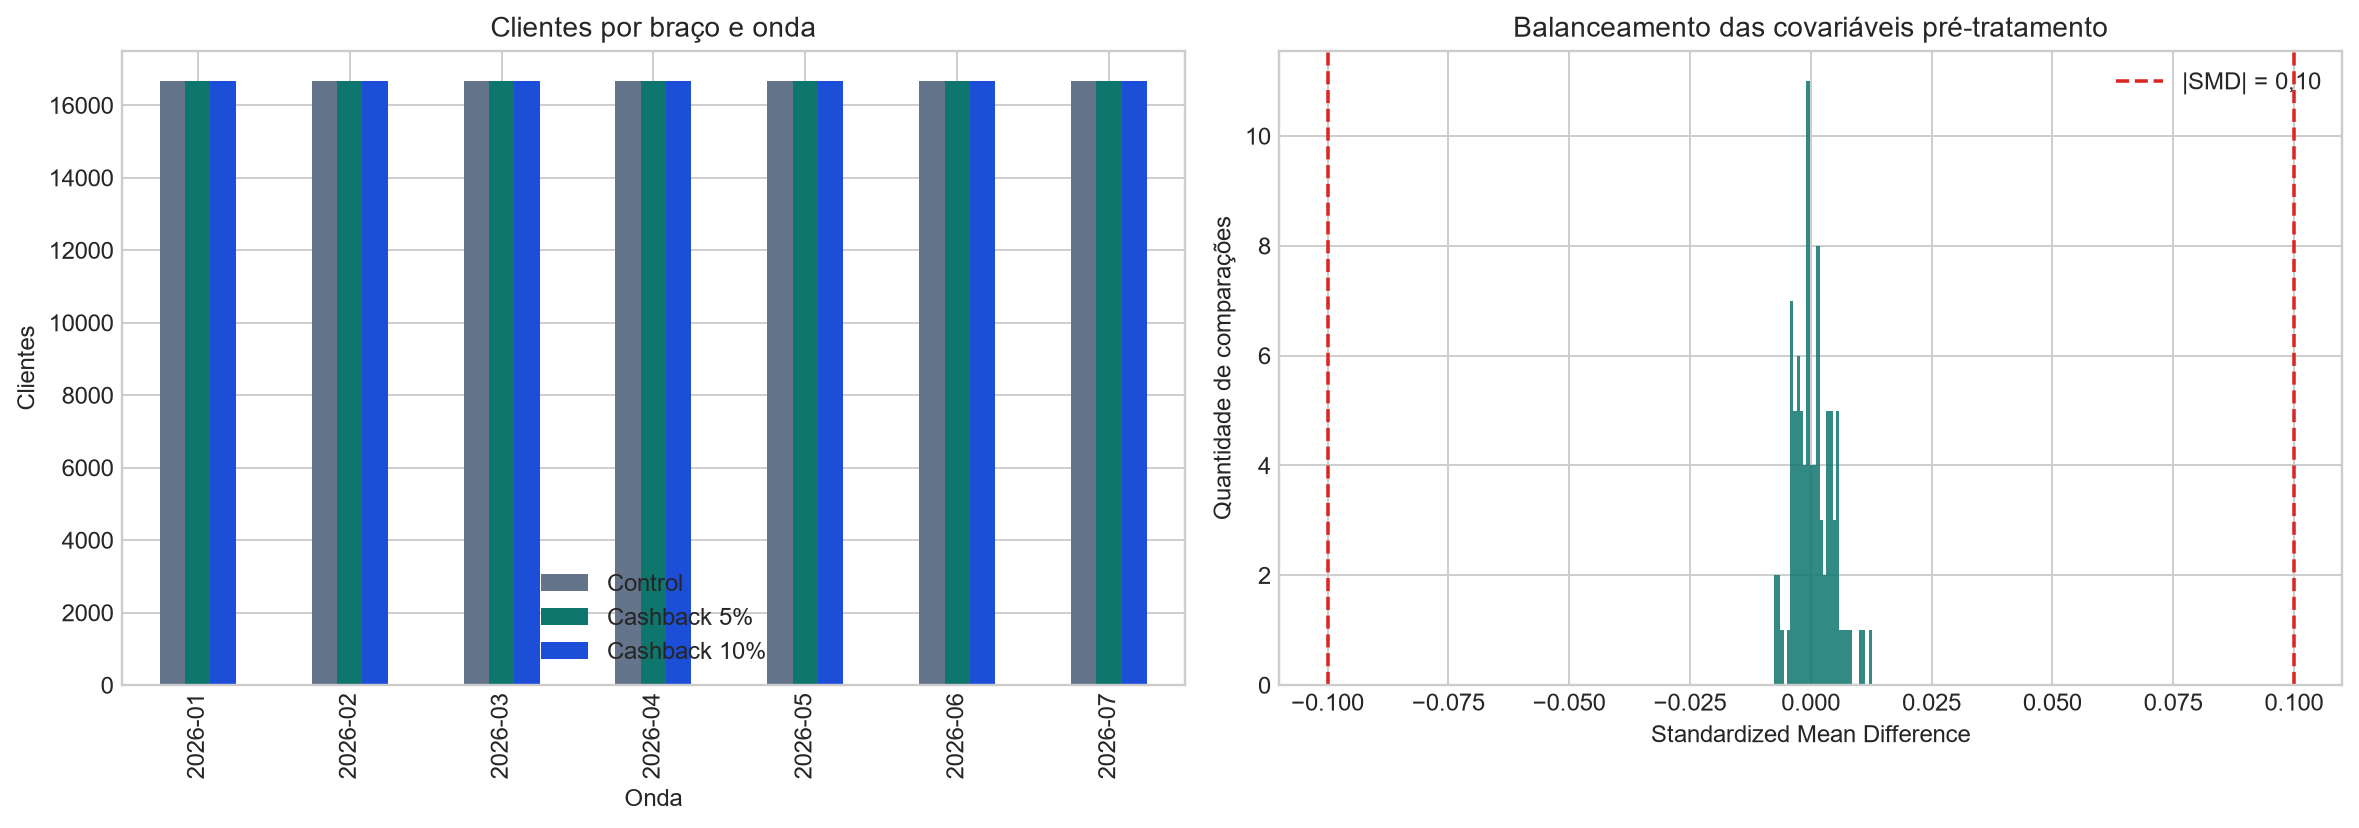

In [4]:
randomization = json.loads((ROOT / "outputs/metrics/randomization_checks.json").read_text(encoding="utf-8"))
smd = pd.read_csv(ROOT / "outputs/tables/pre_treatment_numeric_balance_smd.csv")
assignment = pd.read_csv(ROOT / "outputs/tables/assignment_by_wave.csv")
display(pd.Series(randomization, name="valor").to_frame())
display(assignment)
display(Image(filename=str(ROOT / "outputs/figures/01_randomization_and_balance.png")))

**Análise/Interpretação:** o maior |SMD| é inferior a 0,02 e nenhum sinal pré-tratamento ultrapassa 0,10. Os três braços mantêm proporções praticamente idênticas em todas as ondas. A evidência sustenta a integridade da randomização.

## 6. Non-compliance e variáveis pós-tratamento

Delivery e activation descrevem a execução da campanha. Restringir a análise a clientes entregues ou ativados quebraria a comparabilidade do assignment. Cashback cost, contact cost e engajamento pós-campanha são outcomes ou mediadores, não confundidores pré-tratamento.

,treatment_arm,assigned,delivery_rate,activation_rate,conversion_rate
0,control,116669,0.000000,0.000000,0.273500
1,cashback_5,116669,0.930101,0.576108,0.333199
2,cashback_10,116662,0.929857,0.622782,0.378778


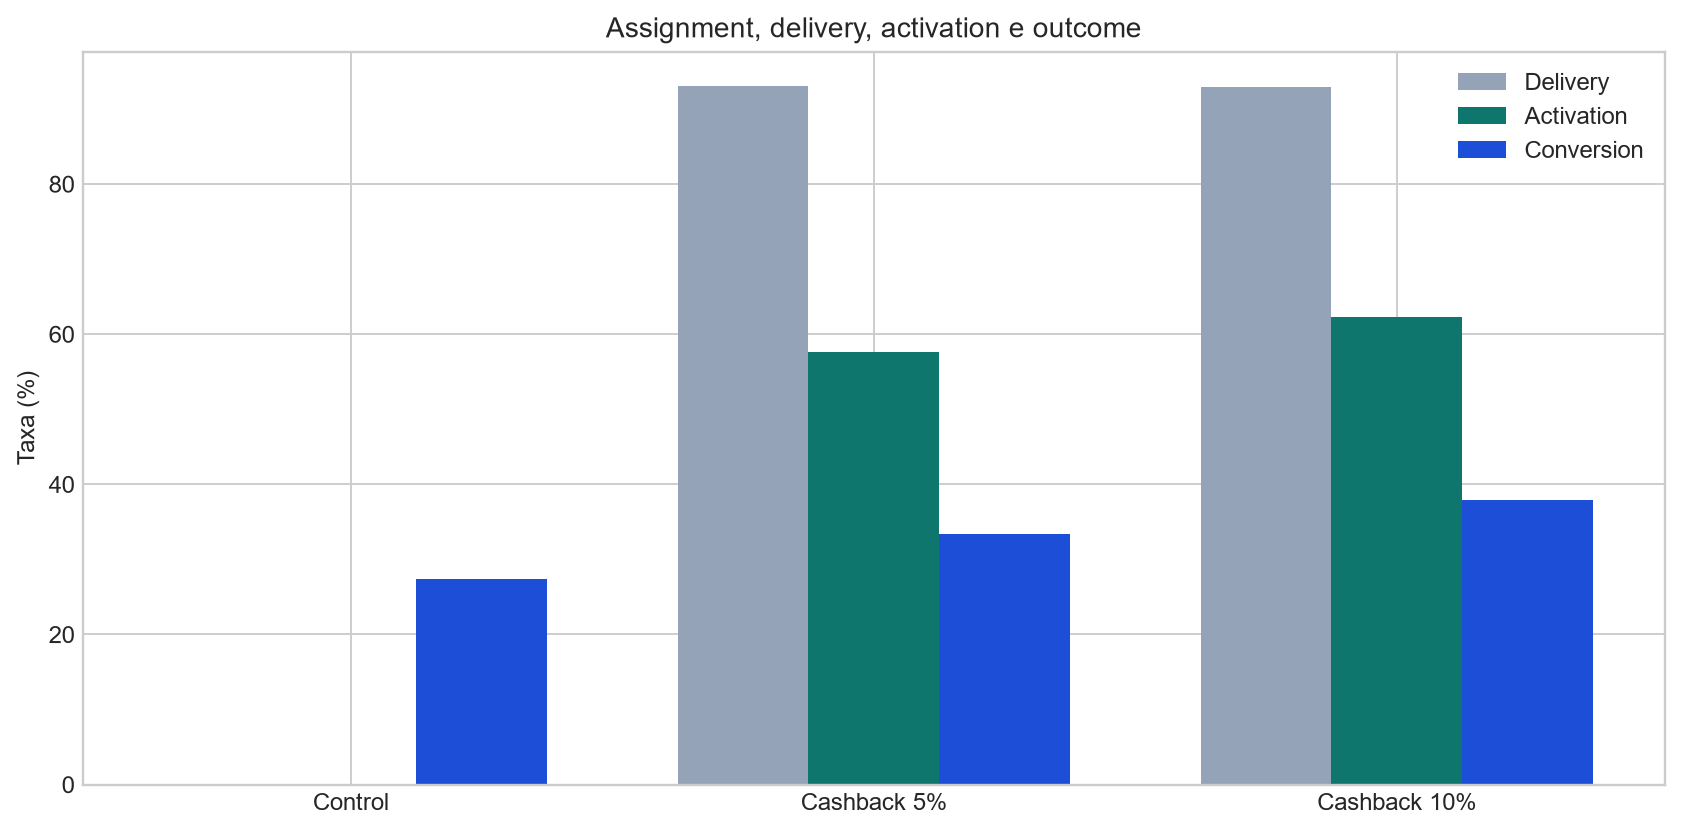

In [5]:
compliance = pd.read_csv(ROOT / "outputs/tables/assignment_delivery_activation.csv")
display(compliance)
display(Image(filename=str(ROOT / "outputs/figures/09_compliance_and_conversion.png")))

## 7. Sample size, power e MDE

Power e MDE deveriam ser definidos antes do experimento. Aqui aparecem como diagnóstico retrospectivo. O tamanho amostral permite detectar aproximadamente 0,61 p.p. em conversão e cerca de R$ 3 por cliente em margem líquida nas ondas 1–5.

In [6]:
power = pd.read_csv(ROOT / "outputs/metrics/power_and_mde_diagnostics.csv")
display(power)

,treatment,metric,n_treatment,n_control,baseline,mde_80pct_power,observed_effect,observed_power_diagnostic
0,cashback_5,purchased_30d,83335,83335,0.265795,0.006063,0.055691,1.0
1,cashback_5,net_margin_30d,83335,83335,74.869889,2.910928,11.007916,1.0
2,cashback_10,purchased_30d,83330,83335,0.265795,0.006063,0.102008,1.0
3,cashback_10,net_margin_30d,83330,83335,74.869889,3.125224,21.305904,1.0


## 8. Efeitos causais e comparações múltiplas

Os efeitos abaixo seguem ITT. Outcomes binários usam diferença de proporções. Métricas contínuas usam diferença de médias com erro padrão de Welch. A família de três contrasts recebe correção de Holm.

,metric,treatment,reference,estimate,ci_low,ci_high,p_value_holm,effect_size
0,purchased_30d,cashback_5,control,0.055691,0.051326,0.060056,1.005834e-137,0.122406
1,purchased_30d,cashback_10,control,0.102008,0.097568,0.106448,0.000000e+00,0.219915
2,purchased_30d,cashback_10,cashback_5,0.046317,0.041759,0.050875,2.893092e-88,0.097509
18,spend_30d_post,cashback_5,control,113.553978,103.472226,123.635730,1.552959e-107,0.108148
19,spend_30d_post,cashback_10,control,239.613396,228.306416,250.920377,0.000000e+00,0.203483
20,spend_30d_post,cashback_10,cashback_5,126.059418,114.117220,138.001617,5.769671e-95,0.101357
21,gross_margin_30d,cashback_5,control,20.772758,18.680238,22.865278,6.328222e-84,0.095318
22,gross_margin_30d,cashback_10,control,42.834318,40.538015,45.130620,6.313407e-291,0.179112
23,gross_margin_30d,cashback_10,cashback_5,22.061559,19.656281,24.466838,3.453514e-72,0.088071
30,net_margin_30d,cashback_5,control,11.007916,8.971442,13.044390,6.448765e-26,0.051901


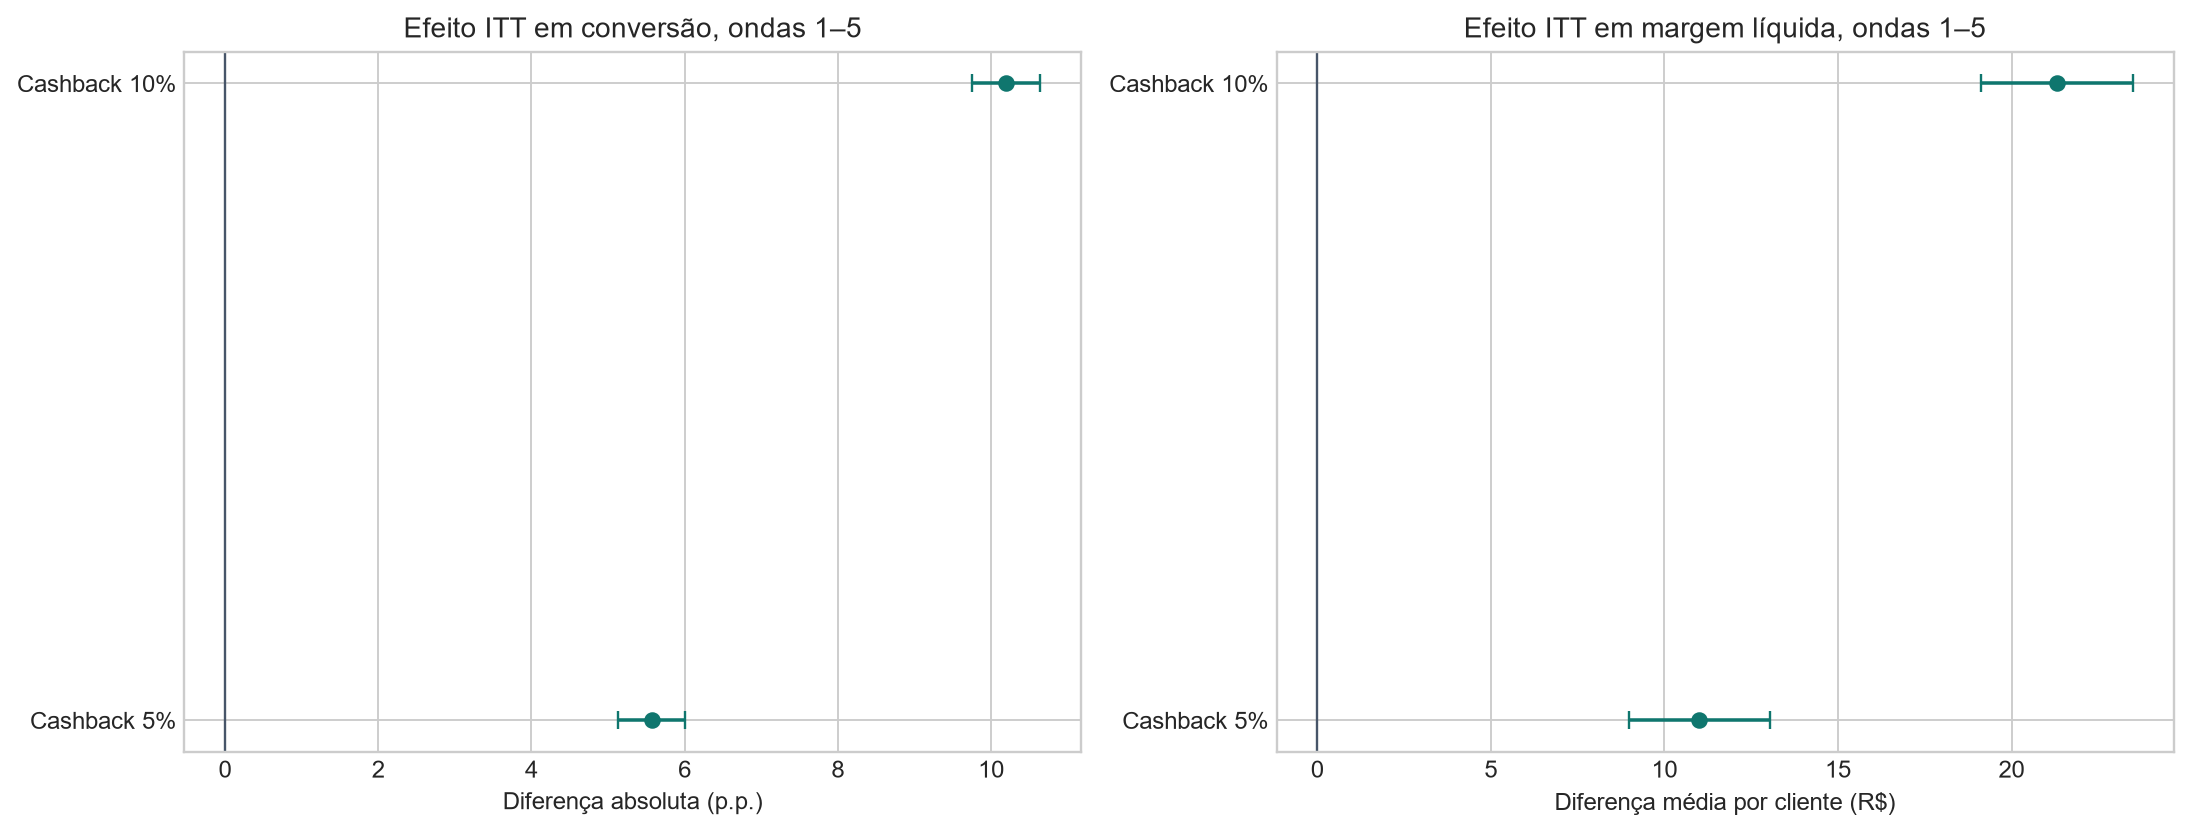

In [7]:
effects = pd.read_csv(ROOT / "outputs/metrics/development_itt_contrasts.csv")
primary = effects[effects.metric.isin(["purchased_30d", "spend_30d_post", "gross_margin_30d", "net_margin_30d"])]
display(primary[["metric", "treatment", "reference", "estimate", "ci_low", "ci_high", "p_value_holm", "effect_size"]])
display(Image(filename=str(ROOT / "outputs/figures/03_primary_causal_effects.png")))

**Análise/Interpretação:** os dois tratamentos aumentam conversão, spend, margem bruta e margem líquida. O braço de 10% produz maior efeito absoluto. Essa constatação ainda não resolve a decisão porque seu custo e a deterioração dos guardrails também são maiores.

## 9. CUPED e robustez das métricas financeiras

CUPED utiliza exclusivamente sinais pré-tratamento. `gross_margin_30d_pre` ajusta as métricas de margem; spend e frequência usam seus respectivos históricos. Theta é estimado no controle das ondas 1–5.

,outcome,covariate,theta_control_development,correlation,variance_reduction
0,spend_30d_post,spend_30d_pre,0.262913,0.424909,0.175899
1,txn_count_30d_post,txn_count_30d_pre,0.362056,0.436690,0.184335
2,gross_margin_30d,gross_margin_30d_pre,0.344651,0.505201,0.245144
3,net_margin_30d,gross_margin_30d_pre,0.344651,0.516808,0.258856


,outcome,covariate,treatment,reference,estimate_cuped,standard_error_cuped,ci_low_cuped,ci_high_cuped,p_value_cuped,p_value_holm_cuped
9,net_margin_30d,gross_margin_30d_pre,cashback_5,control,11.217553,0.906906,9.440037,12.995069,3.983613e-35,7.967226e-35
10,net_margin_30d,gross_margin_30d_pre,cashback_10,control,21.282833,0.957830,19.405506,23.160159,3.211134e-109,9.633401e-109
11,net_margin_30d,gross_margin_30d_pre,cashback_10,cashback_5,10.065280,0.978545,8.147353,11.983207,8.294249e-25,8.294249e-25


,metric,treatment,reference,estimate,bootstrap_ci_low,bootstrap_ci_high,method
0,net_margin_30d,cashback_5,control,11.007916,8.830132,12.893030,"Bayesian bootstrap, 300 draws"
1,net_margin_30d,cashback_10,control,21.305904,18.969187,23.361341,"Bayesian bootstrap, 300 draws"
2,net_margin_30d,cashback_10,cashback_5,10.297988,8.366376,12.509857,"Bayesian bootstrap, 300 draws"


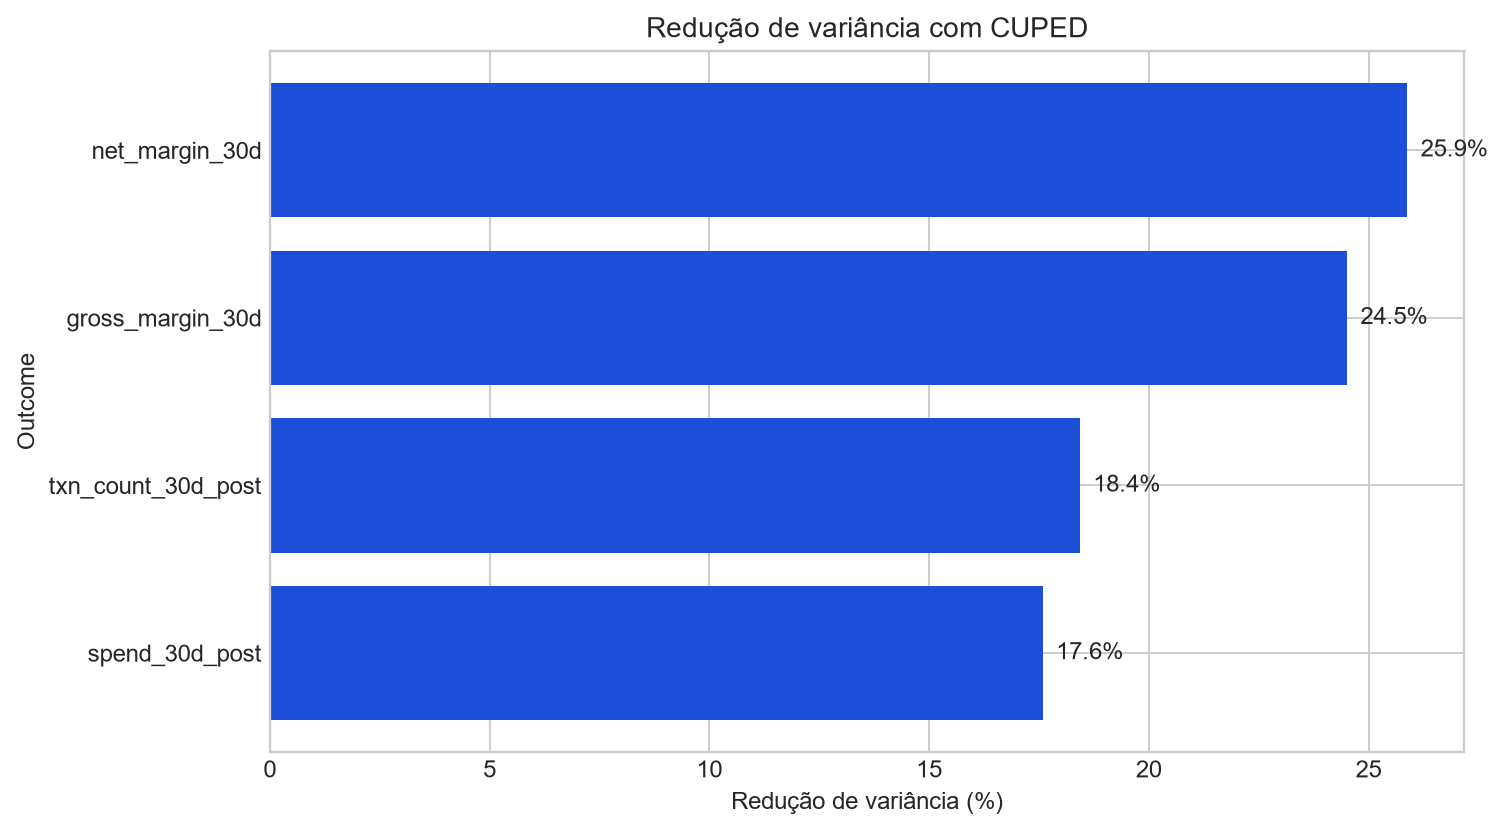

In [8]:
cuped = pd.read_csv(ROOT / "outputs/metrics/cuped_variance_reduction.csv")
cuped_effects = pd.read_csv(ROOT / "outputs/metrics/cuped_contrasts.csv")
bootstrap = pd.read_csv(ROOT / "outputs/metrics/net_margin_bootstrap_intervals.csv")
display(cuped)
display(cuped_effects[cuped_effects.outcome == "net_margin_30d"])
display(bootstrap)
display(Image(filename=str(ROOT / "outputs/figures/04_cuped_variance_reduction.png")))

**Análise/Interpretação:** CUPED reduz aproximadamente 26% da variância de margem líquida sem alterar o estimando causal. O bootstrap confirma intervalos positivos para os três contrasts do KPI primário.

## 10. Lucro incremental, ROI e canibalização

`net_margin_30d` já deduz cashback e custo de contato. O ROI adotado é:

`incremental net profit total / (cashback cost + contact cost)`

O indicador mede eficiência do investimento. Ele não substitui o lucro incremental absoluto.

,cohort,treatment_arm,assigned_customers,purchases,conversion_rate,total_transactions,total_spend,total_gross_margin,total_cashback_cost,total_contact_cost,total_net_margin,mean_net_margin,incremental_conversion_rate_vs_control,incremental_net_margin_per_customer_vs_control,incremental_net_profit_total_vs_control,campaign_cost_total,roi_incremental_net_profit_over_campaign_cost
9,all_waves,control,116669,31909,0.273500,394582,44860133.61,9355883.29,0.00,0.00,9355883.29,80.191682,0.000000,0.000000,0.000000e+00,0.00,NaN
10,all_waves,cashback_5,116669,38874,0.333199,504322,59265093.05,12000816.84,1127434.80,64159.22,10809223.77,92.648636,0.059699,12.456955,1.453340e+06,1191594.02,1.219661
11,all_waves,cashback_10,116662,44189,0.378778,604134,73955951.86,14543503.64,2537332.57,73487.01,11932682.85,102.284230,0.105278,22.092549,2.577361e+06,2610819.58,0.987185


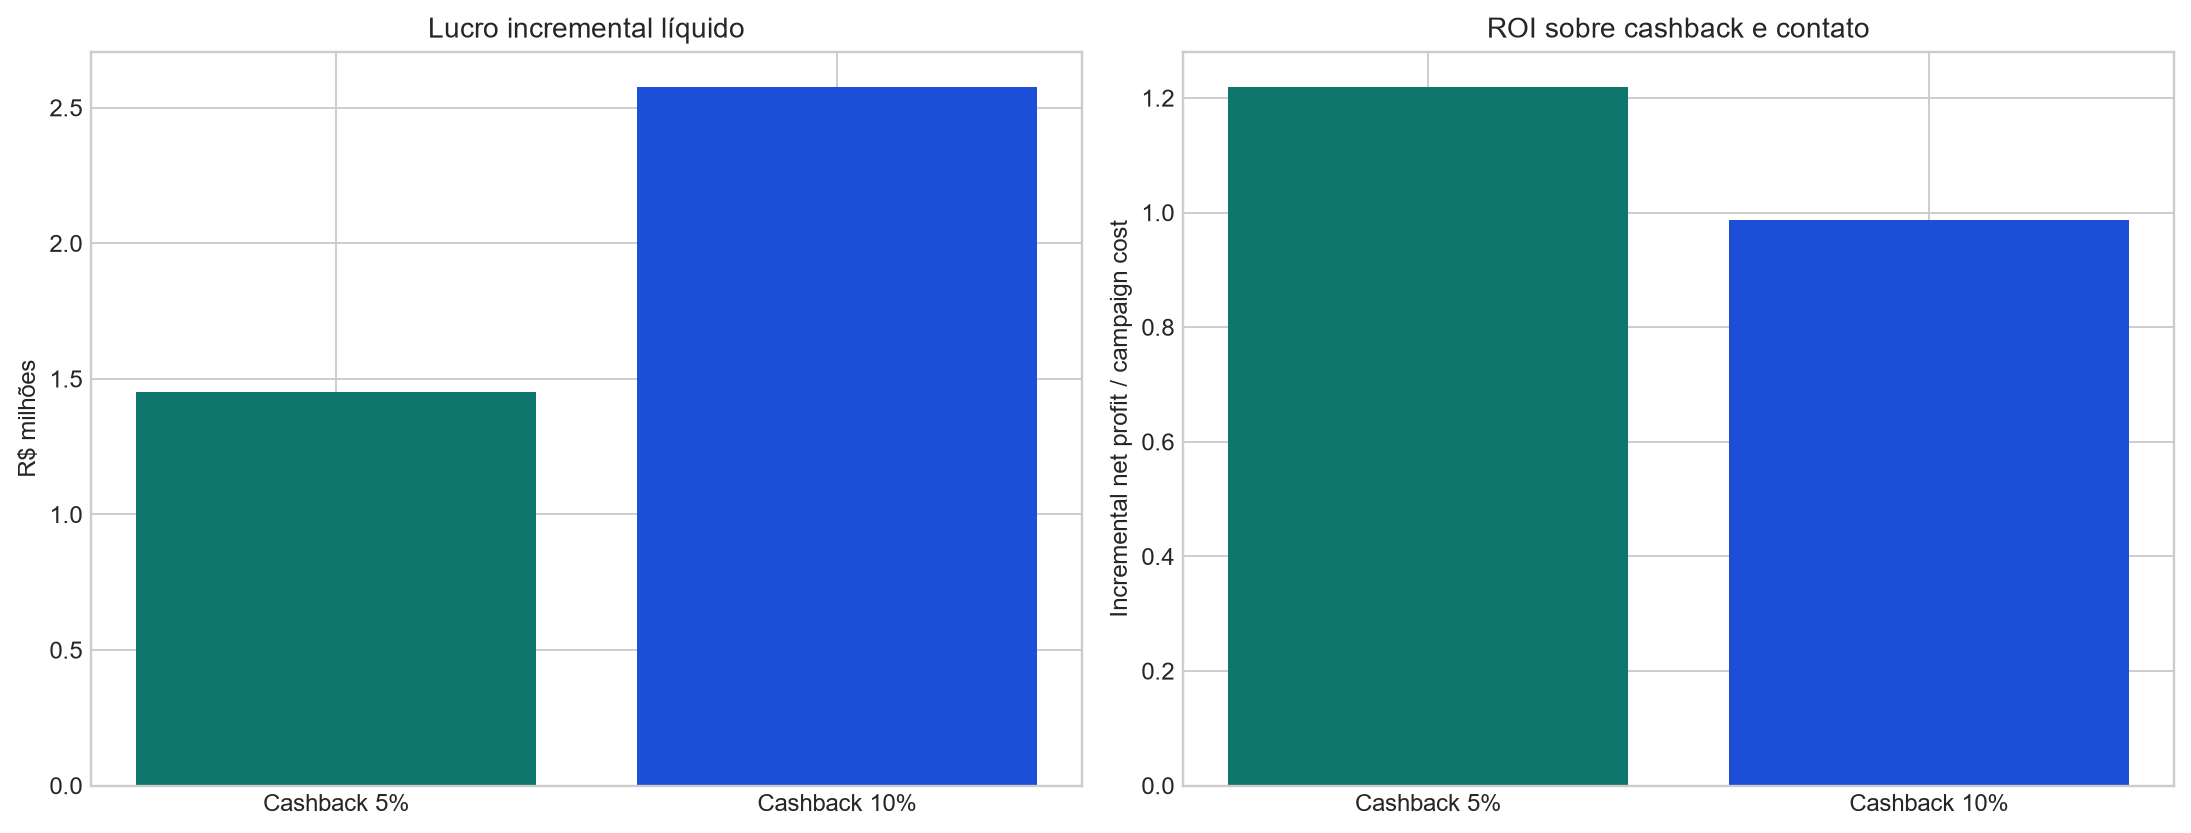

In [9]:
economics = pd.read_csv(ROOT / "outputs/tables/business_economics_by_cohort.csv")
all_waves = economics[economics.cohort == "all_waves"]
display(all_waves)
display(Image(filename=str(ROOT / "outputs/figures/06_incremental_profit_and_roi.png")))

**Análise/Interpretação:** 10% maximiza lucro incremental líquido absoluto, enquanto 5% apresenta ROI superior. A diferença entre gross spend, incremental spend, cashback pago e net margin mostra a canibalização do comportamento que ocorreria sem incentivo.

## 11. Guardrails e congelamento da política

Os limites abaixo são premissas explícitas do case para rollout amplo e exigiriam aprovação de Produto e Risco em uma aplicação real. A política escolhe, entre os braços elegíveis, aquele com maior lucro incremental nas ondas 1–5.

,treatment,guardrail,absolute_change,ci_low,ci_high,p_value_holm,illustrative_max_deterioration,passes_threshold
0,cashback_5,complaint_30d,0.011172,0.009882,0.012462,1.214439e-64,0.015,True
1,cashback_5,refund_flag_30d,0.004680,0.003139,0.006221,2.658693e-09,0.010,True
2,cashback_5,chargeback_flag_30d,0.002244,0.001460,0.003028,2.028179e-08,0.005,True
3,cashback_5,churn_60d,-0.007920,-0.010506,-0.005333,5.871890e-09,0.005,True
4,cashback_10,complaint_30d,0.030086,0.028512,0.031660,9.873801e-307,0.015,False
5,cashback_10,refund_flag_30d,0.012938,0.011285,0.014591,1.159702e-52,0.010,False
6,cashback_10,chargeback_flag_30d,0.005281,0.004413,0.006148,2.355887e-32,0.005,False
7,cashback_10,churn_60d,-0.006295,-0.008894,-0.003696,4.114305e-06,0.005,True


,valor
decision_stage,frozen_before_wave_7_holdout
development_waves,"[2026-01, 2026-02, 2026-03, 2026-04, 2026-05]"
temporal_validation_wave,2026-06
final_holdout_wave,2026-07
primary_estimand,Intention-to-Treat
primary_kpi,net_margin_30d
chosen_policy,cashback_5
guardrail_thresholds_absolute,"{'complaint_30d': 0.015, 'refund_flag_30d': 0...."
guardrail_pass_by_arm,"{'cashback_10': False, 'cashback_5': True}"
rationale,Choose the guardrail-eligible treatment with t...


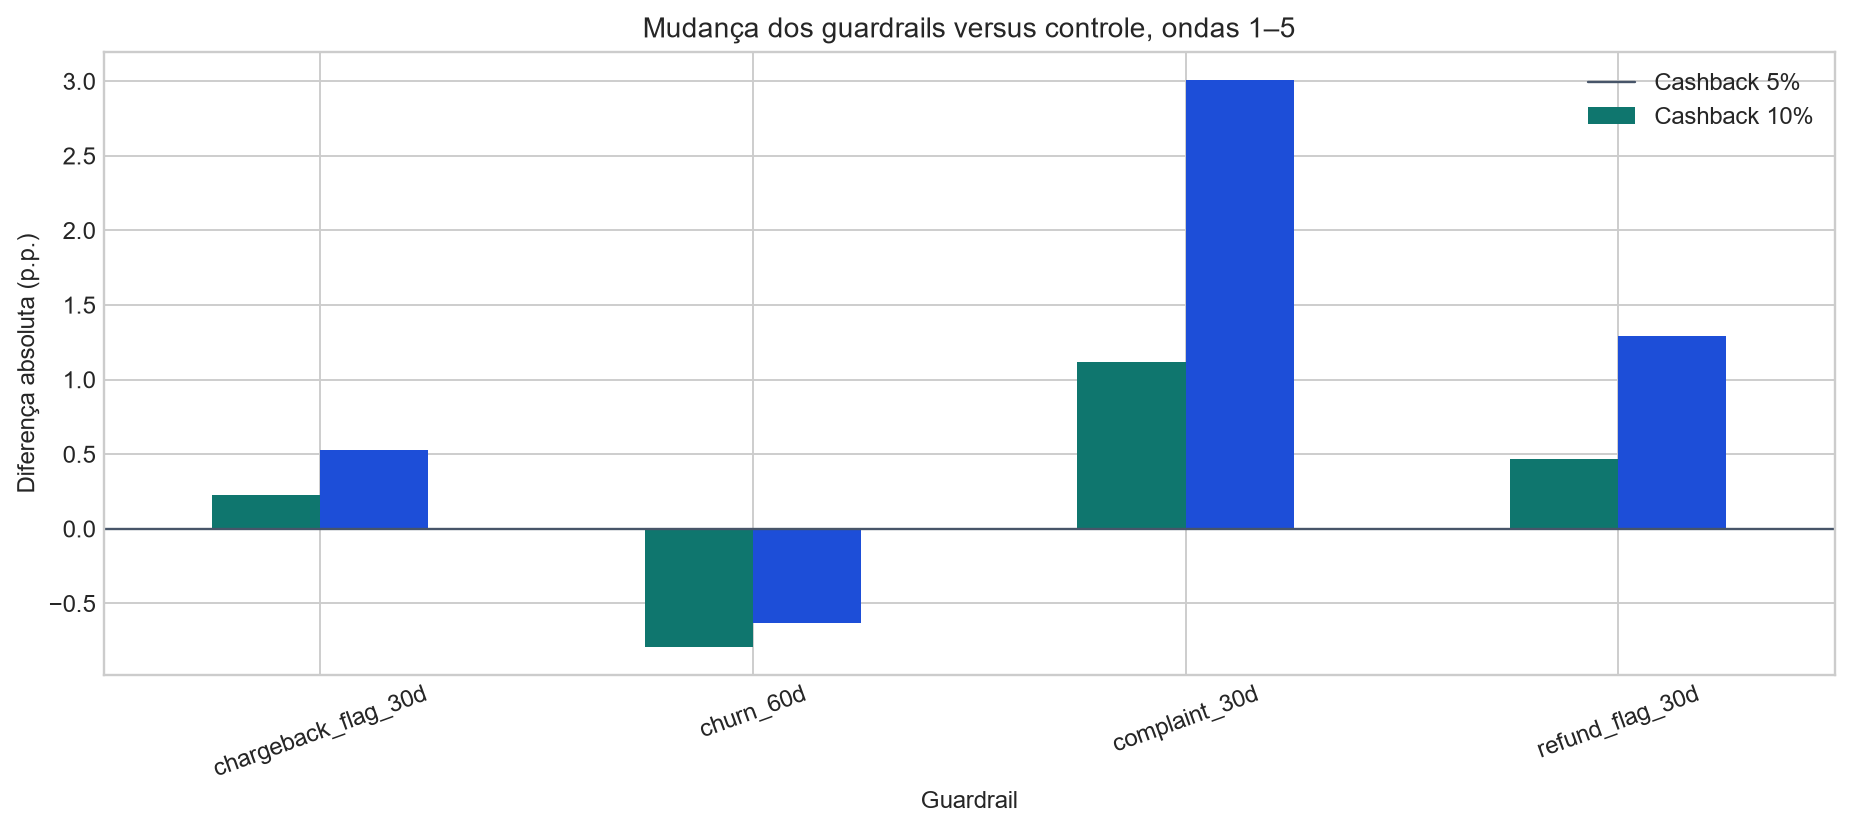

In [10]:
guardrails = pd.read_csv(ROOT / "outputs/tables/development_guardrail_decision.csv")
freeze = json.loads((ROOT / "outputs/metrics/policy_freeze_record.json").read_text(encoding="utf-8"))
display(guardrails)
display(pd.Series(freeze, name="valor").to_frame())
display(Image(filename=str(ROOT / "outputs/figures/07_guardrails.png")))

**Análise/Interpretação:** 5% respeita os limites ilustrativos. 10% ultrapassa os limites de complaints, refunds e chargebacks. A política congelada é cashback de 5% para rollout amplo; 10% permanece como hipótese de piloto restrito ou targeting futuro.

## 12. Validação temporal e holdout final

A onda 6 valida a estabilidade. A onda 7 mede a generalização final da política congelada e não pode redefinir retroativamente a decisão.

,cohort,metric,treatment,reference,estimate,standard_error,ci_low,ci_high,p_value,relative_effect,effect_size,observed_power_diagnostic,p_value_holm
0,temporal_validation_wave_6,purchased_30d,cashback_5,control,0.067259,0.005111,0.057240,0.077277,1.524291e-39,0.231995,0.143945,1.000000,3.048583e-39
3,temporal_validation_wave_6,net_margin_30d,cashback_5,control,15.128525,2.792565,9.654997,20.602053,6.088466e-08,0.164473,0.059344,0.999727,1.217693e-07
6,temporal_validation_wave_6,complaint_30d,cashback_5,control,0.011160,0.001504,0.008211,0.014108,1.182935e-13,0.815789,0.082073,1.000000,1.182935e-13
9,temporal_validation_wave_6,refund_flag_30d,cashback_5,control,0.002940,0.001814,-0.000616,0.006496,1.051350e-01,0.109865,0.017756,0.367284,1.051350e-01
12,temporal_validation_wave_6,chargeback_flag_30d,cashback_5,control,0.000420,0.000877,-0.001299,0.002139,6.319779e-01,0.067308,0.005247,0.076667,6.319779e-01
15,temporal_validation_wave_6,churn_60d,cashback_5,control,-0.004080,0.002880,-0.009724,0.001564,1.565680e-01,-0.053167,-0.015520,0.293844,3.131360e-01


,cohort,metric,treatment,reference,estimate,standard_error,ci_low,ci_high,p_value,relative_effect,effect_size,observed_power_diagnostic,p_value_holm
0,final_holdout_wave_7,purchased_30d,cashback_5,control,0.072179,0.005142,0.062100,0.082257,9.392443e-45,0.244165,0.153511,1.000000,1.878489e-44
3,final_holdout_wave_7,net_margin_30d,cashback_5,control,17.030578,2.780318,11.581055,22.480102,9.147770e-10,0.179249,0.067100,0.999984,1.829554e-09
6,final_holdout_wave_7,complaint_30d,cashback_5,control,0.014100,0.001505,0.011151,0.017049,7.218282e-21,1.151961,0.104310,1.000000,1.443656e-20
9,final_holdout_wave_7,refund_flag_30d,cashback_5,control,0.004980,0.001812,0.001428,0.008532,5.998029e-03,0.193925,0.030127,0.784631,5.998029e-03
12,final_holdout_wave_7,chargeback_flag_30d,cashback_5,control,0.000540,0.000881,-0.001187,0.002267,5.399017e-01,0.086538,0.006716,0.094032,5.399017e-01
15,final_holdout_wave_7,churn_60d,cashback_5,control,-0.006960,0.002907,-0.012658,-0.001262,1.666370e-02,-0.087284,-0.026229,0.667892,4.999111e-02


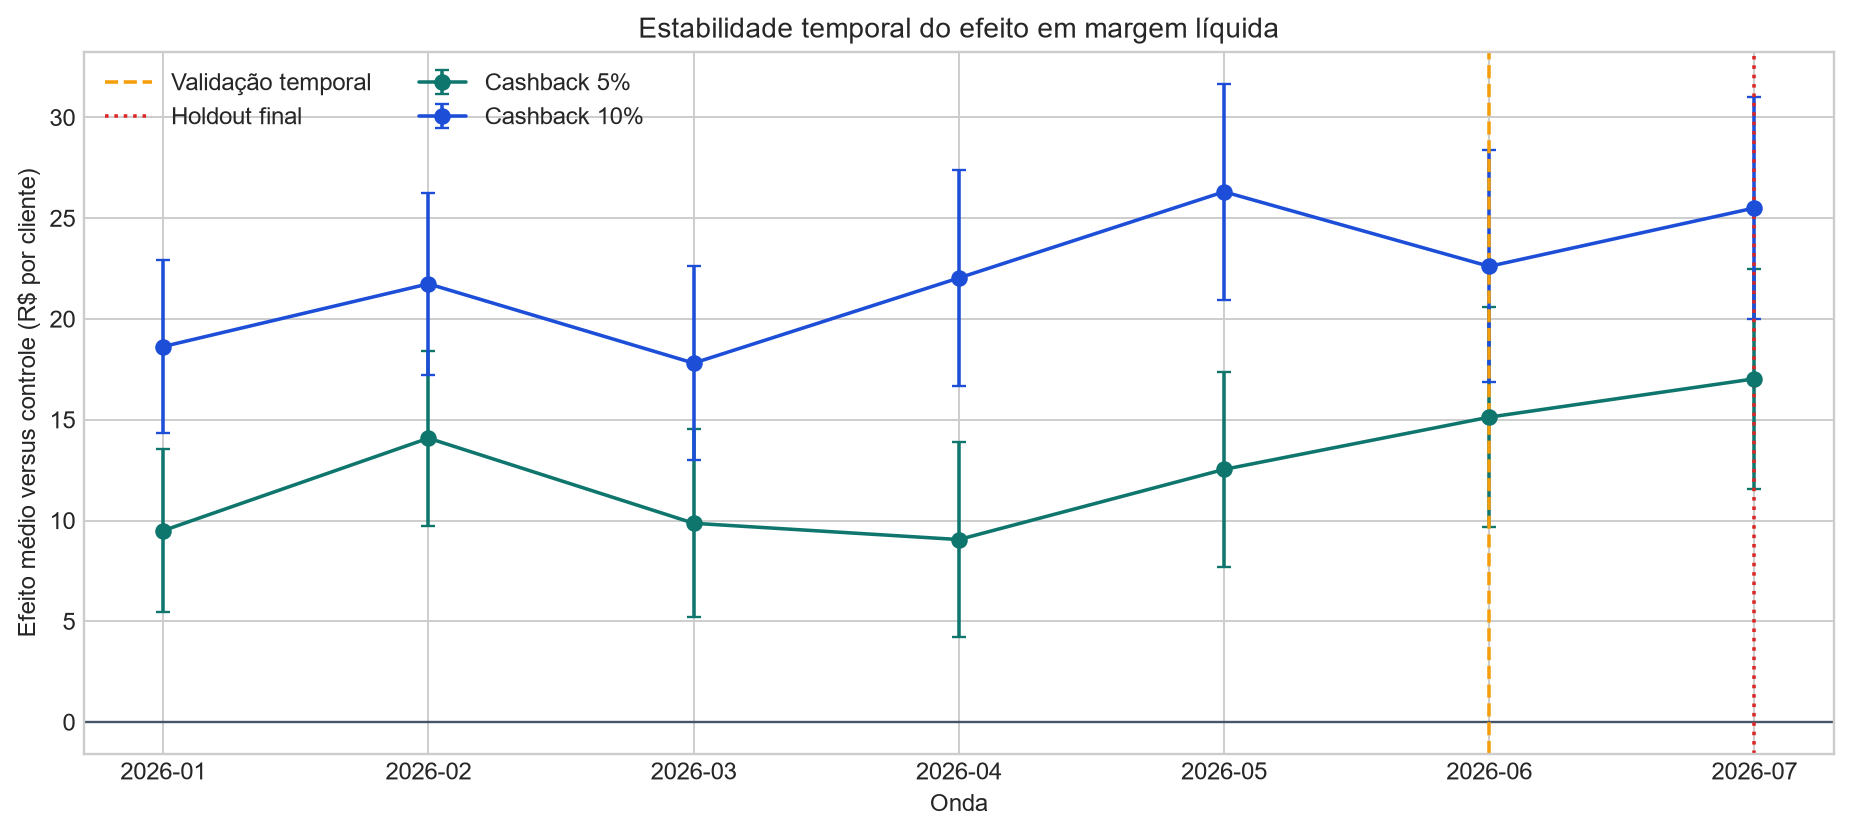

In [11]:
validation = pd.read_csv(ROOT / "outputs/metrics/validation_itt_contrasts.csv")
holdout = pd.read_csv(ROOT / "outputs/metrics/holdout_itt_contrasts.csv")
chosen_validation = validation[(validation.treatment == "cashback_5") & (validation.reference == "control")]
chosen_holdout = holdout[(holdout.treatment == "cashback_5") & (holdout.reference == "control")]
display(chosen_validation)
display(chosen_holdout)
display(Image(filename=str(ROOT / "outputs/figures/05_temporal_stability.png")))

**Análise/Interpretação:** no holdout, cashback de 5% gera +7,22 p.p. de conversão e +R$ 17,03 de margem líquida por cliente. Os intervalos de 95% permanecem positivos. Complaints aumentam, mas o ponto estimado permanece dentro do limite ilustrativo congelado.

## 13. Heterogeneidade exploratória

Os cortes usam apenas dimensões pré-tratamento e servem para gerar hipóteses. Eles não autorizam rollout segmentado sem nova validação, porque múltiplos subgrupos aumentam o risco de descobertas espúrias.

,dimension,level,n_treatment,n_control,net_margin_effect,net_margin_ci_low,net_margin_ci_high,conversion_effect,conversion_ci_low,conversion_ci_high,status
14,baseline_spend_group,Q4,20761,20783,34.432288,27.259870,41.604706,0.066366,0.057256,0.075477,exploratory_hypothesis_generation
4,customer_segment,SMB,7061,6917,20.213057,10.458348,29.967766,0.067387,0.051969,0.082805,exploratory_hypothesis_generation
6,merchant_flag,1,20976,20724,17.317946,11.929644,22.706248,0.060653,0.051788,0.069519,exploratory_hypothesis_generation
3,customer_segment,MicroMerchant,13915,13807,15.822200,9.381068,22.263332,0.057202,0.046368,0.068036,exploratory_hypothesis_generation
8,relationship_tier,Gold,19086,19096,14.291039,10.026535,18.555543,0.059817,0.050666,0.068968,exploratory_hypothesis_generation
9,relationship_tier,Platinum,6662,6720,13.220817,5.967188,20.474445,0.055285,0.039910,0.070660,exploratory_hypothesis_generation
10,relationship_tier,Silver,30923,30765,11.245386,7.952625,14.538147,0.058443,0.051272,0.065615,exploratory_hypothesis_generation
2,customer_segment,Mass,37131,37440,9.310108,6.705719,11.914497,0.053734,0.047255,0.060213,exploratory_hypothesis_generation
5,merchant_flag,0,62359,62611,8.726423,6.705315,10.747531,0.053941,0.048930,0.058953,exploratory_hypothesis_generation
1,customer_segment,Emerging,16382,16376,8.568903,4.811484,12.326322,0.057836,0.048081,0.067591,exploratory_hypothesis_generation


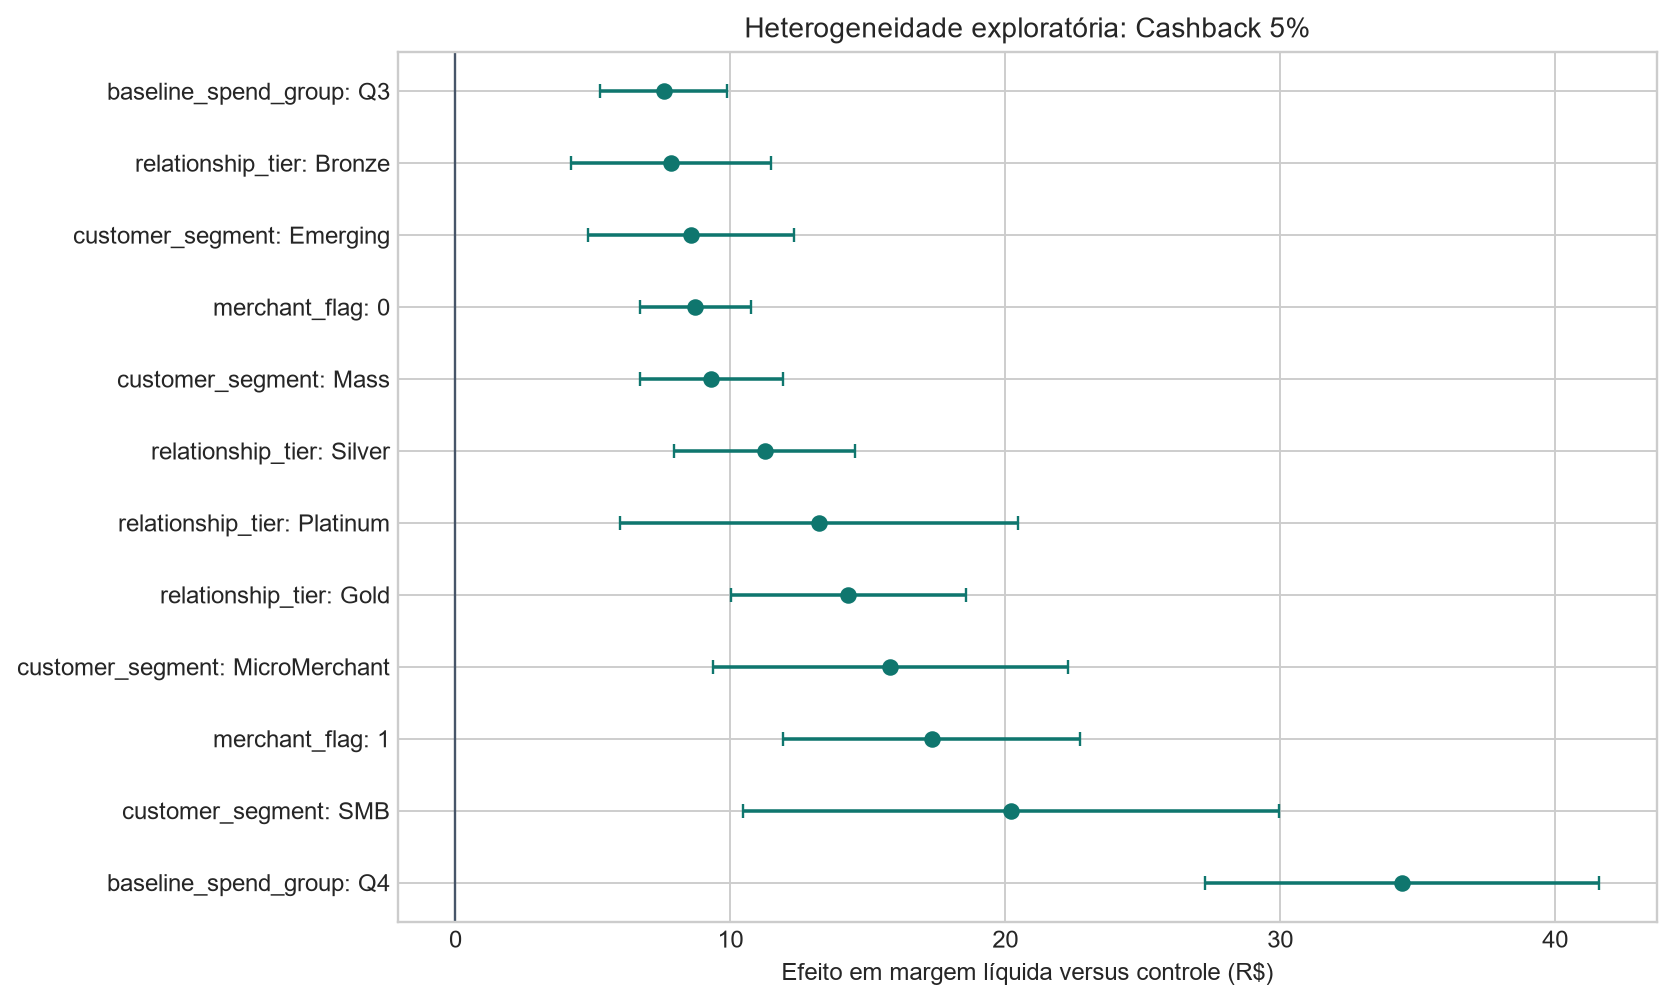

In [12]:
heterogeneity = pd.read_csv(ROOT / "outputs/tables/development_heterogeneous_effects.csv")
display(heterogeneity.sort_values("net_margin_effect", ascending=False).head(15))
display(Image(filename=str(ROOT / "outputs/figures/08_exploratory_heterogeneity.png")))

## 14. Recomendação, limitações e monitoramento

**Recomendação:** avançar com cashback de 5% como política ampla condicionada à aprovação formal dos limites de risco. Manter 10% fora do rollout amplo até testar uma política segmentada com orçamento e guardrails próprios.

Monitorar assignment, delivery, activation, conversão, spend, gross margin, cashback cost, net margin, ROI, complaints, refunds, chargebacks e churn por onda e segmento.

Limitações principais:

- os limites de guardrail são premissas do case, não decisões previamente aprovadas;
- heterogeneidade permanece exploratória;
- ROI depende da definição adotada e não inclui efeitos posteriores aos horizontes observados;
- a análise ITT mede o efeito da oferta atribuída, não o efeito entre clientes que ativaram.

## 15. Conclusão executiva

> Maior conversão não implica maior valor econômico. A decisão deve ser baseada em lucro incremental líquido, incerteza estatística, guardrails e estabilidade do efeito.